<a href="https://colab.research.google.com/github/Patrick190508/whaleshark-mafia-island/blob/main/notebooks/LASSO_Ridge_Ningaloo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LASSO and Ridge — Penalised logistic regression for daily whale shark sightings, Ningaloo Reef

Same question, data and split as `Model_v2_Ningaloo.ipynb`: *will today be a better-than-average day for its season?*
This notebook tests whether adding a penalty to the logistic regression (Ridge or LASSO) improves the prediction, and which environmental variables the model really needs.

## Part 1 — What LASSO and Ridge are

### The starting point: logistic regression
Our model gives each input variable a **coefficient**. The prediction is a weighted sum of the inputs, turned into a probability between 0 and 1. Training chooses the coefficients that fit the training days as well as possible.

**The problem.** With few training days (637) and 12 inputs, the model can give a large coefficient to a variable only because of a chance pattern in those particular days. That coefficient helps on the training seasons and hurts on new seasons.

### The idea: a penalty on the coefficients
Ridge and LASSO add a **penalty** to the training: the model pays a cost for every large coefficient. A variable gets a large weight only if it improves the fit enough to pay that cost.

The strength of the penalty is set by one number, **C**:
- **small C → strong penalty** → small coefficients, simpler model;
- **large C → weak penalty** → close to the normal logistic regression.

C cannot be learned from the training data (the training data always prefer the weakest penalty), so it is chosen on the **validation seasons**.

### Ridge (L2 penalty)
The cost is the **sum of the squared coefficients**. Ridge shrinks all coefficients towards zero, but never exactly to zero: every variable stays in the model, with a smaller weight. It is useful when many variables each carry a little information, or when variables are similar to each other (e.g. `wind` and `wind_3d`), because it shares the weight between them instead of choosing one at random.

### LASSO (L1 penalty)
The cost is the **sum of the absolute values of the coefficients**. With this cost, it is often cheaper to set a coefficient **exactly to zero**, which removes the variable from the model. LASSO therefore also does **variable selection**: the variables that survive are the ones the model needs.

### Note on the earlier notebooks
In scikit-learn, `LogisticRegression()` already uses a Ridge penalty by default, with **C = 1**. The logistic regression of `Model_v2_Ningaloo.ipynb` was therefore already a Ridge model, but with a strength that was never chosen. Here C is chosen on validation, and the model is compared with a version with no penalty at all.


## Part 2 — Aim and process

### Aim
1. **Prediction:** does choosing the penalty improve the ROC-AUC on unseen seasons, compared with the weekly baseline (0.57) and with the logistic regression of the report (0.64)?
2. **Correlations:** which environmental variables does the model keep when it is forced to be simple (LASSO)? This tells us which variables carry real information about good days, and which ones the earlier model used only because of noise.

### Process
1. **Data** — same pipeline as `Model_v2_Ningaloo.ipynb`: Ningaloo, peak season April–June, active seasons (≥ 20 sightings), days with all environmental values.
2. **Target** — `y = 1` if the day has more sightings than the mean of its season.
3. **Split by whole seasons** — train 1998–2004, validation 2005–2006, test 2007–2009.
4. **Inputs** — the same 12 standardised inputs as the report: `sday, sday², sss, sst, sst², chl, wind, wind_3d, wind², wave, wave², moon_illum`.
5. **References** — weekly baseline; logistic regression without penalty; logistic regression of the report (Ridge, C = 1).
6. **Choice of C** — Ridge and LASSO trained for a range of C values; the best C is the one with the highest **validation** ROC-AUC.
7. **Coefficients** — LASSO path (how the coefficients enter the model as the penalty weakens) and comparison of the coefficients of all models.
8. **Stability** — leave-one-season-out on the training seasons: does LASSO select the same variables every time?
9. **Test (used once)** — the chosen models on 2007–2009, at the threshold 0.3 used in the report, overall and season by season.

## Part 3 — Code

### 3.1 Load the daily series and build the season table

In [ ]:
import warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
warnings.filterwarnings("ignore", category=FutureWarning)

URL = "https://raw.githubusercontent.com/Patrick190508/whaleshark-mafia-island/main/data/daily_ningaloo.csv"
d = pd.read_csv(URL, parse_dates=["date"])

PEAK = [4, 5, 6]                                   # Ningaloo season: April–June
d = d[d["month"].isin(PEAK)].copy()
d["sday"] = d.groupby("year").cumcount() + 1       # day of season 1..91
d["week"] = (d["sday"] - 1) // 7 + 1

# active seasons only (>= 20 sightings)
tot = d.groupby("year")["sightings"].sum()
d = d[d["year"].isin(tot[tot >= 20].index)].dropna(subset=["sst", "chl", "sss", "wind", "wave"]).copy()

# squared terms
for c in ["sday", "sst", "wave", "wind"]:
    d[c + "2"] = d[c] ** 2

# target: better-than-average day for its own season
avg = d.groupby("year")["sightings"].transform("mean")
d["y"] = (d["sightings"] > avg).astype(int)

print("seasons:", sorted(d["year"].unique()))
print("rows:", len(d), "| good days:", d["y"].sum(), f"({d['y'].mean():.0%})")

seasons: [np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009)]
rows: 1092 | good days: 404 (37%)


### 3.2 Train / validation / test split by season

In [ ]:
TRAIN, VAL, TEST = list(range(1998, 2005)), [2005, 2006], [2007, 2008, 2009]
train, val, test = d[d["year"].isin(TRAIN)], d[d["year"].isin(VAL)], d[d["year"].isin(TEST)]

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:11s} seasons {part['year'].min()}–{part['year'].max()} | "
          f"days {len(part):4d} | share of good days {part['y'].mean():.0%}")

train       seasons 1998–2004 | days  637 | share of good days 33%
validation  seasons 2005–2006 | days  182 | share of good days 43%
test        seasons 2007–2009 | days  273 | share of good days 42%


### 3.3 Inputs and standardisation (fitted on training only)

In [ ]:
FEATS = ["sday", "sday2", "sss", "sst", "sst2", "chl",
         "wind", "wind_3d", "wind2", "wave", "wave2", "moon_illum"]

scaler = StandardScaler().fit(train[FEATS])
Xtr, Xva, Xte = (scaler.transform(p[FEATS]) for p in (train, val, test))
ytr, yva, yte = train["y"].values, val["y"].values, test["y"].values
print(len(FEATS), "inputs:", FEATS)

12 inputs: ['sday', 'sday2', 'sss', 'sst', 'sst2', 'chl', 'wind', 'wind_3d', 'wind2', 'wave', 'wave2', 'moon_illum']


### 3.4 Model builder and evaluation function
`make_logit` builds a logistic regression with no penalty, Ridge or LASSO. It works with both older and newer versions of scikit-learn (the way of choosing the penalty changed in version 1.8).

In [ ]:
NEW_API = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)

def make_logit(kind, C=1.0):
    """kind = 'none' (no penalty), 'ridge' (L2) or 'lasso' (L1). Small C = strong penalty."""
    if kind == "none":
        return (LogisticRegression(C=np.inf, max_iter=5000) if NEW_API
                else LogisticRegression(penalty=None, max_iter=5000))
    if kind == "ridge":
        return (LogisticRegression(C=C, l1_ratio=0, max_iter=5000) if NEW_API
                else LogisticRegression(penalty="l2", C=C, max_iter=5000))
    if kind == "lasso":
        return (LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=5000) if NEW_API
                else LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=5000))

def evaluate(y_true, p, thr=0.3, label=""):
    """Metrics at threshold thr, plus ROC-AUC (threshold-free)."""
    pred = (np.asarray(p) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"model": label, "thr": thr,
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, p),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

def table(rows):
    return pd.DataFrame(rows).set_index("model").round(2)

### 3.5 References: weekly baseline, no penalty, model of the report
- **Weekly baseline:** share of good days per week of the season in training.
- **No penalty:** plain logistic regression.
- **Report model:** `LogisticRegression()` with default settings = Ridge with C = 1.

In [ ]:
week_share = train.groupby("week")["y"].mean()
def baseline_prob(df):
    return df["week"].map(week_share).fillna(train["y"].mean()).values

m_none   = make_logit("none").fit(Xtr, ytr)
m_report = make_logit("ridge", 1.0).fit(Xtr, ytr)

rows = [evaluate(yva, baseline_prob(val),           label="weekly baseline"),
        evaluate(yva, m_none.predict_proba(Xva)[:, 1],   label="logistic, no penalty"),
        evaluate(yva, m_report.predict_proba(Xva)[:, 1], label="logistic of the report (Ridge, C=1)")]
print("Validation seasons 2005–2006, threshold 0.3")
table(rows)

Validation seasons 2005–2006, threshold 0.3


,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
weekly baseline,0.3,0.58,0.51,0.72,0.60,0.61,57,55,22,48
"logistic, no penalty",0.3,0.64,0.56,0.82,0.66,0.70,65,52,14,51
"logistic of the report (Ridge, C=1)",0.3,0.63,0.55,0.80,0.65,0.71,63,52,16,51


### 3.6 Choice of C on the validation seasons
Ridge and LASSO are trained on 1998–2004 for 25 values of C, from very strong (0.001) to very weak (100) penalty. For each model we record the validation ROC-AUC and how many coefficients are different from zero.

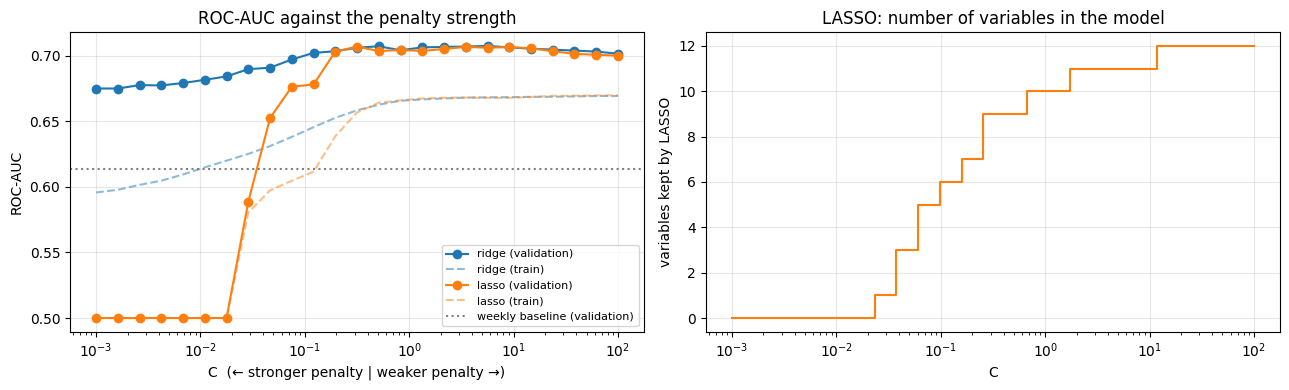

best ridge: C = 5.6234 | validation ROC-AUC 0.707 | variables kept 12
best lasso: C = 0.3162 | validation ROC-AUC 0.707 | variables kept 9


In [ ]:
Cs = np.logspace(-3, 2, 25)
rows = []
for kind in ["ridge", "lasso"]:
    for c in Cs:
        m = make_logit(kind, c).fit(Xtr, ytr)
        rows.append({"model": kind, "C": c,
                     "auc_train": roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1]),
                     "auc_val":   roc_auc_score(yva, m.predict_proba(Xva)[:, 1]),
                     "nonzero":   int((np.abs(m.coef_[0]) > 1e-8).sum())})
grid = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for kind, colour in [("ridge", "tab:blue"), ("lasso", "tab:orange")]:
    g = grid[grid["model"] == kind]
    axes[0].plot(g["C"], g["auc_val"], "o-", color=colour, label=f"{kind} (validation)")
    axes[0].plot(g["C"], g["auc_train"], "--", color=colour, alpha=0.5, label=f"{kind} (train)")
axes[0].axhline(roc_auc_score(yva, baseline_prob(val)), color="grey", ls=":", label="weekly baseline (validation)")
axes[0].set_xscale("log"); axes[0].set_xlabel("C  (← stronger penalty | weaker penalty →)")
axes[0].set_ylabel("ROC-AUC"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[0].set_title("ROC-AUC against the penalty strength")

g = grid[grid["model"] == "lasso"]
axes[1].step(g["C"], g["nonzero"], where="mid", color="tab:orange")
axes[1].set_xscale("log"); axes[1].set_xlabel("C"); axes[1].set_ylabel("variables kept by LASSO")
axes[1].set_yticks(range(0, len(FEATS) + 1, 2)); axes[1].grid(alpha=0.3)
axes[1].set_title("LASSO: number of variables in the model")
plt.tight_layout(); plt.show()

best = {kind: grid[grid["model"] == kind].sort_values("auc_val", ascending=False).iloc[0]
        for kind in ["ridge", "lasso"]}
for kind, b in best.items():
    print(f"best {kind:5s}: C = {b.C:.4f} | validation ROC-AUC {b.auc_val:.3f} | variables kept {b.nonzero}")

### 3.7 LASSO path — in which order do the variables enter the model?
Each line is one coefficient. Moving from left (strong penalty) to right (weak penalty), the variables enter the model one by one: the first to enter are the most useful. The dashed line marks the C chosen on validation.

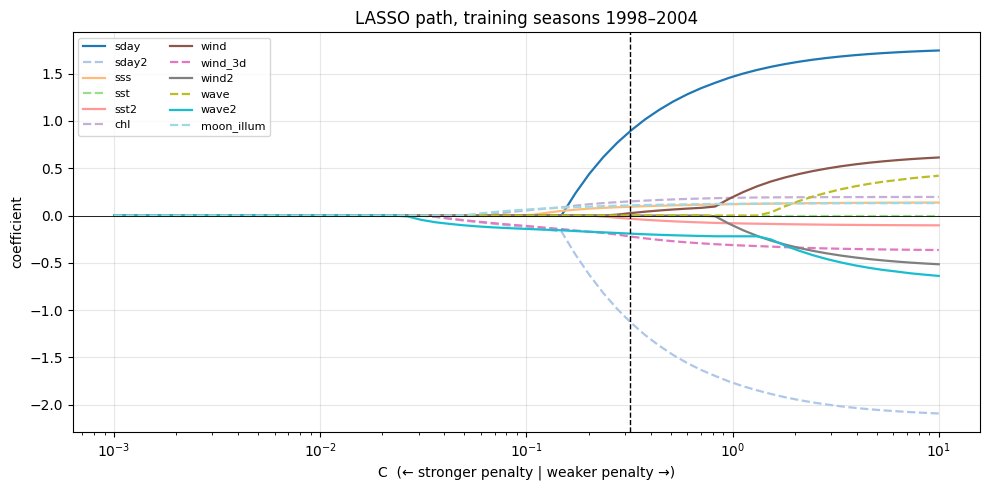

Order in which the variables enter the model:
wave2                          C = 0.0265
sday2                          C = 0.0363
wind_3d                        C = 0.0363
moon_illum                     C = 0.0495
chl                            C = 0.0677
sss                            C = 0.1081
sday                           C = 0.1727
sst2                           C = 0.2360
wind                           C = 0.2759
wind2                          C = 0.8227
wave                           C = 1.5362
sst           never selected (C up to 10)


In [ ]:
path_C = np.logspace(-3, 1, 60)
path = pd.DataFrame([make_logit("lasso", c).fit(Xtr, ytr).coef_[0] for c in path_C],
                    index=path_C, columns=FEATS)

plt.figure(figsize=(10, 5))
colours = plt.cm.tab20(np.linspace(0, 1, len(FEATS)))
for i, col in enumerate(FEATS):
    plt.plot(path.index, path[col], label=col, color=colours[i],
             ls="-" if i % 2 == 0 else "--", lw=1.6)
plt.axvline(best["lasso"].C, color="k", ls="--", lw=1)
plt.axhline(0, color="k", lw=0.6)
plt.xscale("log"); plt.xlabel("C  (← stronger penalty | weaker penalty →)"); plt.ylabel("coefficient")
plt.title("LASSO path, training seasons 1998–2004")
plt.legend(ncol=2, fontsize=8, loc="upper left"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# order of entry: first C at which each coefficient becomes non-zero
entry = {col: path.index[(path[col].abs() > 1e-8).values].min() for col in FEATS}
print("Order in which the variables enter the model:")
print(pd.Series(entry).sort_values().apply(
    lambda c: f"C = {c:.4f}" if pd.notna(c) else "never selected (C up to 10)").to_string())

### 3.8 Coefficients of the chosen models
All inputs are standardised, so the coefficients can be compared: sign = direction (up or down), size = how much the model relies on that variable. A zero in the LASSO column means the variable was removed.

,no penalty,report (C=1),Ridge (C=5.62),LASSO (C=0.316)
sday,1.59,1.34,1.66,0.89
sday2,-1.90,-1.66,-2.00,-1.12
sss,0.12,0.13,0.14,0.09
sst,4.25,0.08,0.50,0.00
sst2,-4.34,-0.18,-0.60,-0.03
chl,0.20,0.18,0.19,0.15
wind,0.65,0.47,0.60,0.02
wind_3d,-0.37,-0.34,-0.36,-0.22
wind2,-0.55,-0.37,-0.50,0.00
wave,0.46,0.22,0.42,0.00


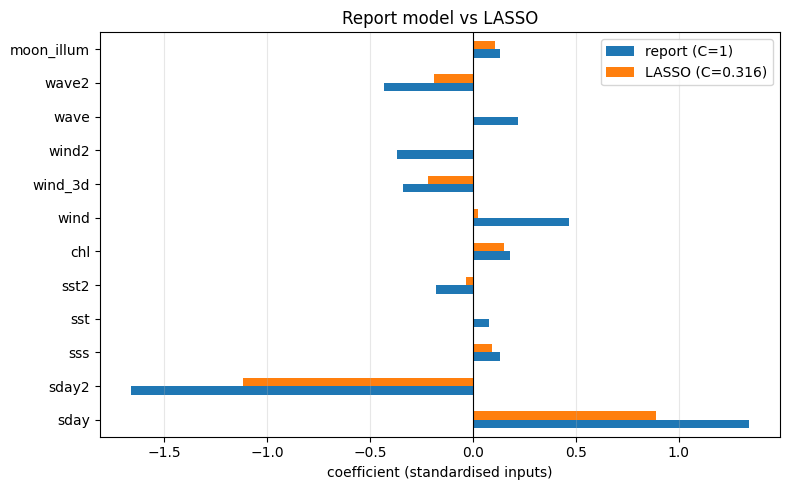

In [ ]:
m_ridge = make_logit("ridge", best["ridge"].C).fit(Xtr, ytr)
m_lasso = make_logit("lasso", best["lasso"].C).fit(Xtr, ytr)

coefs = pd.DataFrame({"no penalty":      m_none.coef_[0],
                      "report (C=1)":    m_report.coef_[0],
                      f"Ridge (C={best['ridge'].C:.3g})": m_ridge.coef_[0],
                      f"LASSO (C={best['lasso'].C:.3g})": m_lasso.coef_[0]}, index=FEATS)
display(coefs.round(2))

ax = coefs.iloc[:, [1, 3]].plot.barh(figsize=(8, 5), color=["tab:blue", "tab:orange"])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("coefficient (standardised inputs)")
ax.set_title("Report model vs LASSO"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

### 3.9 Stability of the LASSO selection (leave-one-season-out)
LASSO is refitted 7 times, each time leaving out one training season, with the same C. If a variable is selected in (almost) every fit, its selection does not depend on one particular season.

In [ ]:
sel = {}
for yr in TRAIN:
    sub = train[train["year"] != yr]
    m = make_logit("lasso", best["lasso"].C).fit(scaler.transform(sub[FEATS]), sub["y"])
    sel[f"without {yr}"] = pd.Series(m.coef_[0], index=FEATS)
sel = pd.DataFrame(sel)
summary = pd.DataFrame({"times selected (of 7)": (sel.abs() > 1e-8).sum(axis=1),
                        "same sign every time": np.sign(sel.replace(0, np.nan)).nunique(axis=1) <= 1,
                        "mean coefficient": sel.mean(axis=1).round(2)})
summary.sort_values("times selected (of 7)", ascending=False)

,times selected (of 7),same sign every time,mean coefficient
sday,7,True,0.74
sday2,7,True,-0.98
wind_3d,7,True,-0.21
chl,7,True,0.13
wave2,7,True,-0.19
sss,6,True,0.09
moon_illum,6,True,0.11
wind,4,True,0.03
sst2,4,True,-0.09
sst,1,True,0.04


### 3.10 Test on unseen seasons (used once)
Threshold 0.3, as chosen on validation in `Model_v2_Ningaloo.ipynb`. The test seasons are used only here, after all choices have been made.

In [ ]:
THR = 0.3
models = {"logistic, no penalty": m_none, "logistic of the report (Ridge, C=1)": m_report,
          f"Ridge, C={best['ridge'].C:.3g}": m_ridge, f"LASSO, C={best['lasso'].C:.3g}": m_lasso}

rows = [evaluate(yte, baseline_prob(test), THR, "weekly baseline")]
rows += [evaluate(yte, m.predict_proba(Xte)[:, 1], THR, name) for name, m in models.items()]
print(f"Test seasons 2007–2009 | always 'good' -> precision {yte.mean():.2f}")
results_test = table(rows)
results_test

Test seasons 2007–2009 | always 'good' -> precision 0.42


,thr,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
weekly baseline,0.3,0.54,0.47,0.69,0.56,0.57,79,89,36,69
"logistic, no penalty",0.3,0.59,0.51,0.71,0.60,0.64,82,78,33,80
"logistic of the report (Ridge, C=1)",0.3,0.61,0.53,0.75,0.62,0.64,86,77,29,81
"Ridge, C=5.62",0.3,0.59,0.51,0.70,0.59,0.64,81,78,34,80
"LASSO, C=0.316",0.3,0.60,0.52,0.76,0.61,0.64,87,81,28,77


In [ ]:
# Test ROC-AUC season by season
rows = []
for yr in TEST:
    mask = (test["year"] == yr).values
    r = {"season": yr, "weekly baseline": roc_auc_score(yte[mask], baseline_prob(test)[mask])}
    for name, m in models.items():
        r[name] = roc_auc_score(yte[mask], m.predict_proba(Xte[mask])[:, 1])
    rows.append(r)
pd.DataFrame(rows).set_index("season").round(2)

,weekly baseline,"logistic, no penalty","logistic of the report (Ridge, C=1)","Ridge, C=5.62","LASSO, C=0.316"
season,,,,,
2007,0.48,0.54,0.52,0.53,0.5
2008,0.62,0.69,0.70,0.69,0.7
2009,0.61,0.69,0.69,0.69,0.7
